In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

from pathlib import Path

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

print("Environment ready!")

Environment ready!


In [2]:
BASE_DIR = Path.cwd().parent
DATA_DIR = BASE_DIR / "data" / "processed"

ipo_master = pd.read_csv(DATA_DIR / "ipo_master_analysis.csv")
ipo_returns = pd.read_csv(DATA_DIR / "ipo_returns_analysis.csv")
ipo_subscription = pd.read_csv(DATA_DIR / "ipo_subscription_data.csv")
ipo_sector = pd.read_csv(DATA_DIR / "ipo_sector_mapping_final.csv")
historical_prices = pd.read_csv(DATA_DIR / "historical_stock_prices.csv")

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [3]:
datasets = {
    "IPO Master": ipo_master,
    "IPO Returns": ipo_returns,
    "IPO Subscription": ipo_subscription,
    "IPO Sector": ipo_sector,
    "Historical Prices": historical_prices
}

for name, df in datasets.items():
    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print("Missing Values:", df.isnull().sum().sum())
    print("Duplicate Rows:", df.duplicated().sum())


IPO Master
Shape: (194, 43)
Columns: ['COMPANY NAME', 'SECURITY TYPE', 'ISSUE PRICE', 'SYMBOL', 'ISSUE START DATE', 'ISSUE END DATE', 'PRICE RANGE', 'DATE OF LISTING', 'PRICE_STATUS', 'YF_TICKER', 'ISSUE PRICE_RETURNS', 'LISTING DATE', 'LISTING CLOSE', 'LISTING RETURN (%)', '6M TARGET DATE', '6M ACTUAL DATE', '6M CLOSE', '6M RETURN (%)', '12M TARGET DATE', '12M ACTUAL DATE', '12M CLOSE', '12M RETURN (%)', '6M DELAY DAYS', '12M DELAY DAYS', 'LISTING DATE_SUBSCRIPTION', 'QIB SUBSCRIPTION', 'NII SUBSCRIPTION', 'RETAIL SUBSCRIPTION', 'TOTAL SUBSCRIPTION', 'SUBSCRIPTION SOURCE', 'DATA STATUS', 'SUBSCRIPTION BASIS', 'FINAL DATA', 'QIB BID', 'NII BID', 'RETAIL BID', 'EMPLOYEE BID', 'SECTOR', 'INDUSTRY', 'SECTOR SOURCE', 'SECTOR STATUS', 'LISTING TO 6M RETURN (%)', 'LISTING TO 12M RETURN (%)']
Missing Values: 859
Duplicate Rows: 0

IPO Returns
Shape: (194, 16)
Columns: ['COMPANY NAME', 'YF_TICKER', 'ISSUE PRICE', 'LISTING DATE', 'LISTING CLOSE', 'LISTING RETURN (%)', '6M TARGET DATE', '6M ACT

# 2. Data Quality Assessment

This section evaluates missing values, data types, duplicate records,
date consistency and data completeness across all datasets.

In [4]:
# Missing value analysis

missing_analysis = pd.DataFrame({
    "Missing Count": ipo_master.isnull().sum(),
    "Missing Percentage": (
        ipo_master.isnull().mean() * 100
    ).round(2),
    "Available Records": ipo_master.notnull().sum()
})

missing_analysis = (
    missing_analysis
    .sort_values("Missing Percentage", ascending=False)
)

missing_analysis

,Missing Count,Missing Percentage,Available Records
NII BID,193,99.48,1
EMPLOYEE BID,193,99.48,1
RETAIL BID,193,99.48,1
QIB BID,193,99.48,1
LISTING TO 6M RETURN (%),9,4.64,185
LISTING RETURN (%),9,4.64,185
LISTING CLOSE,9,4.64,185
LISTING TO 12M RETURN (%),9,4.64,185
6M CLOSE,4,2.06,190
QIB SUBSCRIPTION,4,2.06,190


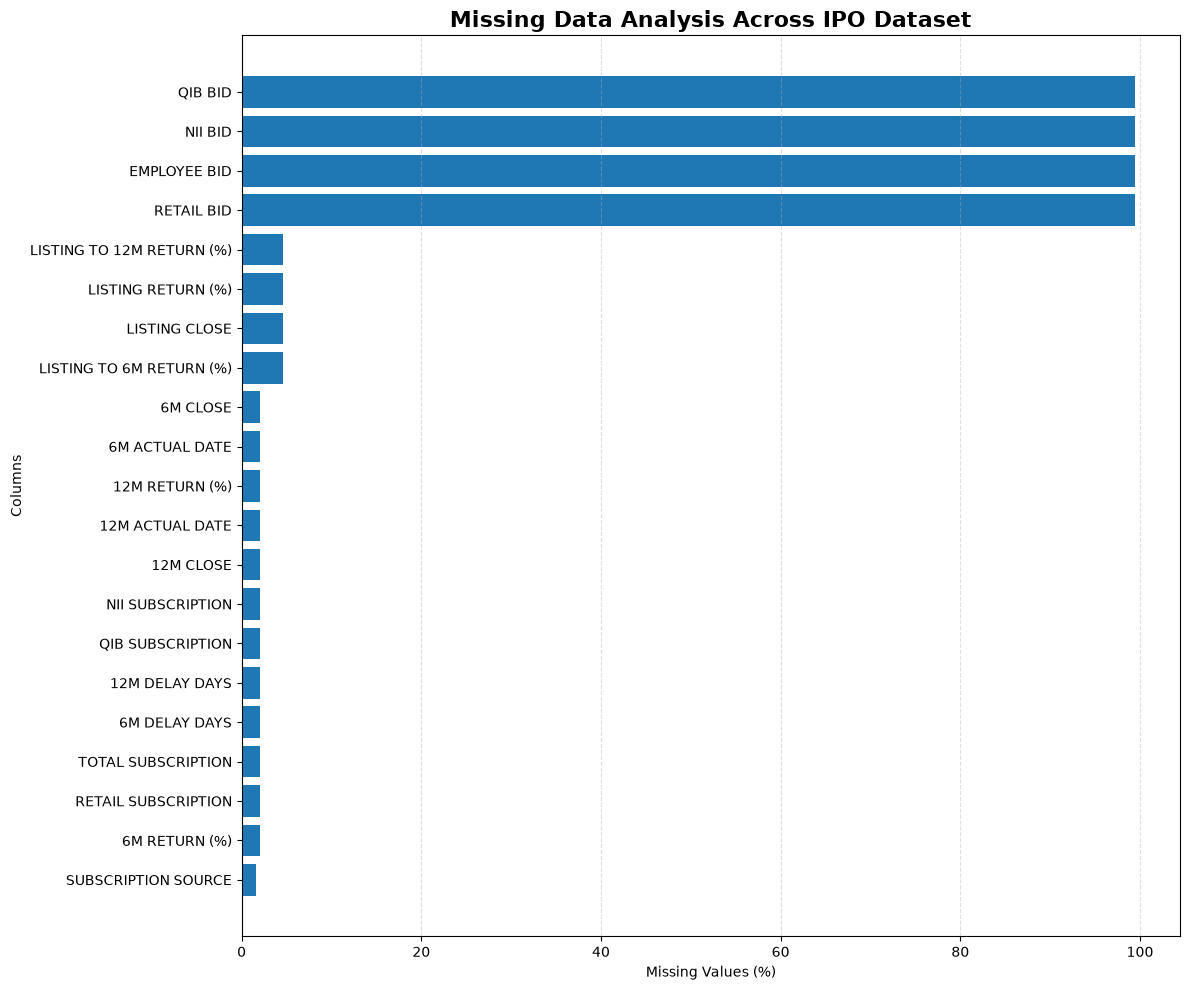

In [5]:
missing_plot = missing_analysis[
    missing_analysis["Missing Count"] > 0
].sort_values("Missing Percentage")

plt.figure(figsize=(12, 10))

plt.barh(
    missing_plot.index,
    missing_plot["Missing Percentage"]
)

plt.title(
    "Missing Data Analysis Across IPO Dataset",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Missing Values (%)")
plt.ylabel("Columns")

plt.grid(axis="x", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

In [6]:
# Inspect data types

dtype_analysis = pd.DataFrame({
    "Column": ipo_master.columns,
    "Data Type": ipo_master.dtypes.astype(str).values,
    "Unique Values": ipo_master.nunique().values
})

dtype_analysis

,Column,Data Type,Unique Values
0,COMPANY NAME,str,194
1,SECURITY TYPE,str,1
2,ISSUE PRICE,float64,169
3,SYMBOL,str,194
4,ISSUE START DATE,str,151
5,ISSUE END DATE,str,149
6,PRICE RANGE,str,183
7,DATE OF LISTING,str,151
8,PRICE_STATUS,str,1
9,YF_TICKER,str,194


In [7]:
date_columns = [
    "ISSUE START DATE",
    "ISSUE END DATE",
    "DATE OF LISTING",
    "LISTING DATE",
    "6M TARGET DATE",
    "6M ACTUAL DATE",
    "12M TARGET DATE",
    "12M ACTUAL DATE"
]

for col in date_columns:
    ipo_master[col] = pd.to_datetime(
        ipo_master[col],
        errors="coerce"
    )

print("Date conversion completed.")

Date conversion completed.


In [8]:
print("Earliest IPO listing date:",
      ipo_master["DATE OF LISTING"].min())

print("Latest IPO listing date:",
      ipo_master["DATE OF LISTING"].max())

print("\nIPO records by listing year:")

ipo_master["LISTING YEAR"] = (
    ipo_master["DATE OF LISTING"].dt.year
)

print(
    ipo_master["LISTING YEAR"]
    .value_counts()
    .sort_index()
)

Earliest IPO listing date: 2022-11-15 00:00:00
Latest IPO listing date: 2025-10-24 00:00:00

IPO records by listing year:
LISTING YEAR
2022    15
2023    47
2024    71
2025    61
Name: count, dtype: int64


In [9]:
key_columns = [
    "ISSUE PRICE",
    "LISTING CLOSE",
    "LISTING RETURN (%)",
    "6M RETURN (%)",
    "12M RETURN (%)",
    "LISTING TO 6M RETURN (%)",
    "LISTING TO 12M RETURN (%)",
    "QIB SUBSCRIPTION",
    "NII SUBSCRIPTION",
    "RETAIL SUBSCRIPTION",
    "TOTAL SUBSCRIPTION"
]

ipo_master[key_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
ISSUE PRICE,194.00,403.44,292.35,25.00,216.00,333.00,499.00,"1,960.00"
LISTING CLOSE,185.00,476.09,386.05,16.19,217.97,368.15,557.05,"2,338.90"
LISTING RETURN (%),185.00,17.53,33.10,-92.02,-2.73,10.32,32.18,162.60
6M RETURN (%),190.00,23.36,60.47,-93.15,-15.79,11.49,54.67,290.68
12M RETURN (%),190.00,35.61,83.65,-92.37,-19.14,16.44,58.02,426.62
LISTING TO 6M RETURN (%),185.00,5.49,42.66,-59.12,-20.73,-3.43,21.21,187.97
LISTING TO 12M RETURN (%),185.00,15.65,61.69,-63.82,-27.30,-1.01,32.66,261.06
QIB SUBSCRIPTION,190.00,77.80,76.53,1.01,8.62,51.31,134.06,331.60
NII SUBSCRIPTION,190.00,52.14,76.60,0.20,3.85,28.30,63.20,503.83
RETAIL SUBSCRIPTION,190.00,18.91,33.53,0.11,2.13,7.13,21.17,246.94


In [10]:
print("Total IPO records:", len(ipo_master))

print(
    "Unique companies:",
    ipo_master["COMPANY NAME"].nunique()
)

print(
    "Unique symbols:",
    ipo_master["SYMBOL"].nunique()
)

print(
    "Missing company names:",
    ipo_master["COMPANY NAME"].isna().sum()
)

print(
    "Missing listing dates:",
    ipo_master["DATE OF LISTING"].isna().sum()
)

print(
    "Missing issue prices:",
    ipo_master["ISSUE PRICE"].isna().sum()
)

Total IPO records: 194
Unique companies: 194
Unique symbols: 194
Missing company names: 0
Missing listing dates: 0
Missing issue prices: 0


## 3. Return Calculation Validation

Independently recalculate IPO returns using issue price,
listing-day closing price, 6-month closing price and
12-month closing price.

Compare calculated values with the existing dataset
to identify any inconsistencies.

In [11]:
# Create a validation copy
validation_df = ipo_master.copy()

# Recalculate returns independently
validation_df["CALC_LISTING_RETURN"] = (
    (validation_df["LISTING CLOSE"] - validation_df["ISSUE PRICE"])
    / validation_df["ISSUE PRICE"]
) * 100

validation_df["CALC_6M_RETURN"] = (
    (validation_df["6M CLOSE"] - validation_df["ISSUE PRICE"])
    / validation_df["ISSUE PRICE"]
) * 100

validation_df["CALC_12M_RETURN"] = (
    (validation_df["12M CLOSE"] - validation_df["ISSUE PRICE"])
    / validation_df["ISSUE PRICE"]
) * 100

validation_df["CALC_LISTING_TO_6M"] = (
    (validation_df["6M CLOSE"] - validation_df["LISTING CLOSE"])
    / validation_df["LISTING CLOSE"]
) * 100

validation_df["CALC_LISTING_TO_12M"] = (
    (validation_df["12M CLOSE"] - validation_df["LISTING CLOSE"])
    / validation_df["LISTING CLOSE"]
) * 100

# Compare calculated and existing returns
comparisons = {
    "LISTING RETURN (%)": "CALC_LISTING_RETURN",
    "6M RETURN (%)": "CALC_6M_RETURN",
    "12M RETURN (%)": "CALC_12M_RETURN",
    "LISTING TO 6M RETURN (%)": "CALC_LISTING_TO_6M",
    "LISTING TO 12M RETURN (%)": "CALC_LISTING_TO_12M"
}

validation_results = []

for original, calculated in comparisons.items():

    difference = (
        validation_df[original] - validation_df[calculated]
    ).abs()

    validation_results.append({
        "Return Metric": original,
        "Comparable Records": difference.notna().sum(),
        "Maximum Difference": difference.max(),
        "Mismatches Above 0.01": (difference > 0.01).sum()
    })

validation_report = pd.DataFrame(validation_results)

validation_report

,Return Metric,Comparable Records,Maximum Difference,Mismatches Above 0.01
0,LISTING RETURN (%),185,0.00,0
1,6M RETURN (%),190,0.00,0
2,12M RETURN (%),190,0.00,0
3,LISTING TO 6M RETURN (%),185,0.00,0
4,LISTING TO 12M RETURN (%),185,0.00,0


In [12]:
cohort_conditions = [
    (ipo_master["DATE OF LISTING"] >= "2022-10-30") &
    (ipo_master["DATE OF LISTING"] < "2023-10-30"),

    (ipo_master["DATE OF LISTING"] >= "2023-10-30") &
    (ipo_master["DATE OF LISTING"] < "2024-10-30"),

    (ipo_master["DATE OF LISTING"] >= "2024-10-30") &
    (ipo_master["DATE OF LISTING"] < "2025-10-30")
]

cohort_labels = [
    "2022-23",
    "2023-24",
    "2024-25"
]

ipo_master["LISTING COHORT"] = np.select(
    cohort_conditions,
    cohort_labels,
    default="Outside Period"
)

cohort_summary = (
    ipo_master
    .groupby("LISTING COHORT")
    .agg(
        IPO_COUNT=("COMPANY NAME", "count"),
        AVG_LISTING_RETURN=("LISTING RETURN (%)", "mean"),
        MEDIAN_LISTING_RETURN=("LISTING RETURN (%)", "median"),
        AVG_6M_RETURN=("6M RETURN (%)", "mean"),
        MEDIAN_6M_RETURN=("6M RETURN (%)", "median"),
        AVG_12M_RETURN=("12M RETURN (%)", "mean"),
        MEDIAN_12M_RETURN=("12M RETURN (%)", "median")
    )
    .round(2)
)

cohort_summary

,IPO_COUNT,AVG_LISTING_RETURN,MEDIAN_LISTING_RETURN,AVG_6M_RETURN,MEDIAN_6M_RETURN,AVG_12M_RETURN,MEDIAN_12M_RETURN
LISTING COHORT,,,,,,,
2022-23,45,10.51,3.38,37.50,23.19,65.86,31.85
2023-24,67,26.63,19.48,37.02,23.80,36.82,20.05
2024-25,82,13.43,7.35,3.90,-2.16,17.75,-5.77


## 4. Cohort Performance and Profitability Analysis

Compare average returns, median returns, available observations
and percentage of profitable IPOs across listing cohorts.

In [13]:
# Return metrics to analyse
return_metrics = {
    "LISTING RETURN (%)": "Listing",
    "6M RETURN (%)": "6M",
    "12M RETURN (%)": "12M"
}

cohort_results = []

for cohort, group in ipo_master.groupby("LISTING COHORT"):

    if cohort == "Outside Period":
        continue

    for column, label in return_metrics.items():

        returns = group[column].dropna()

        cohort_results.append({
            "LISTING COHORT": cohort,
            "PERIOD": label,
            "AVAILABLE IPOs": len(returns),
            "AVERAGE RETURN (%)": returns.mean(),
            "MEDIAN RETURN (%)": returns.median(),
            "POSITIVE IPOs": (returns > 0).sum(),
            "NEGATIVE IPOs": (returns < 0).sum(),
            "PROFITABLE IPO (%)": (returns > 0).mean() * 100
        })

cohort_detailed = pd.DataFrame(cohort_results)

cohort_detailed = cohort_detailed.round(2)

cohort_detailed

,LISTING COHORT,PERIOD,AVAILABLE IPOs,AVERAGE RETURN (%),MEDIAN RETURN (%),POSITIVE IPOs,NEGATIVE IPOs,PROFITABLE IPO (%)
0,2022-23,Listing,43,10.51,3.38,27,16,62.79
1,2022-23,6M,44,37.50,23.19,33,11,75.00
2,2022-23,12M,44,65.86,31.85,33,11,75.00
3,2023-24,Listing,67,26.63,19.48,52,15,77.61
4,2023-24,6M,67,37.02,23.80,47,20,70.15
5,2023-24,12M,67,36.82,20.05,41,26,61.19
6,2024-25,Listing,75,13.43,7.35,49,26,65.33
7,2024-25,6M,79,3.90,-2.16,38,41,48.10
8,2024-25,12M,79,17.75,-5.77,37,42,46.84


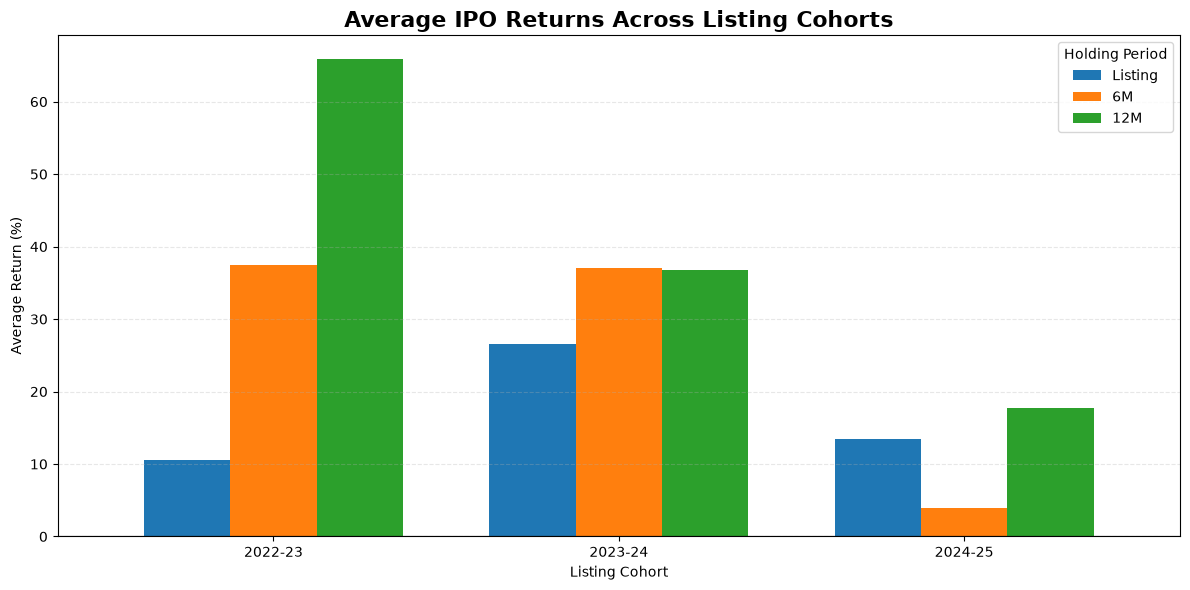

In [14]:
period_order = ["Listing", "6M", "12M"]

plot_data = cohort_detailed.pivot(
    index="LISTING COHORT",
    columns="PERIOD",
    values="AVERAGE RETURN (%)"
)

plot_data = plot_data[period_order]

ax = plot_data.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.75
)

plt.title(
    "Average IPO Returns Across Listing Cohorts",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Listing Cohort")
plt.ylabel("Average Return (%)")

plt.axhline(0, color="black", linewidth=0.8)

plt.xticks(rotation=0)
plt.legend(title="Holding Period")
plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

## 5. IPO Return Distribution and Outlier Analysis

Investigate the distribution of IPO returns using quartiles,
interquartile range (IQR), skewness and extreme observations.

In [15]:
return_columns = [
    "LISTING RETURN (%)",
    "6M RETURN (%)",
    "12M RETURN (%)",
    "LISTING TO 6M RETURN (%)",
    "LISTING TO 12M RETURN (%)"
]

outlier_results = []

for col in return_columns:

    data = ipo_master[col].dropna()

    Q1 = data.quantile(0.25)
    Q2 = data.median()
    Q3 = data.quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = data[
        (data < lower_bound) |
        (data > upper_bound)
    ]

    outlier_results.append({
        "Metric": col,
        "Count": len(data),
        "Q1": Q1,
        "Median": Q2,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": len(outliers),
        "Skewness": data.skew()
    })

outlier_summary = pd.DataFrame(outlier_results)

outlier_summary.round(2)

,Metric,Count,Q1,Median,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Skewness
0,LISTING RETURN (%),185,-2.73,10.32,32.18,34.92,-55.10,84.56,11,0.82
1,6M RETURN (%),190,-15.79,11.49,54.67,70.47,-121.49,160.37,5,1.61
2,12M RETURN (%),190,-19.14,16.44,58.02,77.16,-134.89,173.76,13,1.91
3,LISTING TO 6M RETURN (%),185,-20.73,-3.43,21.21,41.93,-83.63,84.11,9,1.56
4,LISTING TO 12M RETURN (%),185,-27.30,-1.01,32.66,59.96,-117.24,122.61,14,1.65


In [16]:
performance_columns = [
    "LISTING RETURN (%)",
    "6M RETURN (%)",
    "12M RETURN (%)"
]

for col in performance_columns:

    print("\n", "=" * 65)
    print("METRIC:", col)
    print("=" * 65)

    print("\nTOP 10 IPOs")

    display(
        ipo_master.nlargest(10, col)[
            ["COMPANY NAME", "SYMBOL", "DATE OF LISTING", col, "SECTOR"]
        ]
    )

    print("\nBOTTOM 10 IPOs")

    display(
        ipo_master.nsmallest(10, col)[
            ["COMPANY NAME", "SYMBOL", "DATE OF LISTING", col, "SECTOR"]
        ]
    )


METRIC: LISTING RETURN (%)

TOP 10 IPOs


,COMPANY NAME,SYMBOL,DATE OF LISTING,LISTING RETURN (%),SECTOR
49,Tata Technologies Limited,TATATECH,2023-11-30,162.60,Technology
102,Bajaj Housing Finance Limited,BAJAJHFL,2024-09-16,135.71,Financial Services
107,KRN Heat Exchanger and Refrigeration Limited,KRN,2024-10-03,117.63,Technology
97,Unicommerce eSolutions Limited,UNIECOM,2024-08-13,94.52,Technology
21,Ideaforge Technology Limited,IDEAFORGE,2023-07-07,92.70,Industrials
24,Utkarsh Small Finance Bank Limited,UTKARSHBNK,2023-07-21,92.00,Financial Services
120,One MobiKwik Systems Limited,MOBIKWIK,2024-12-18,89.25,Technology
99,Premier Energies Limited,PREMIERENE,2024-09-03,86.64,Technology
25,Netweb Technologies India Limited,NETWEB,2023-07-27,82.08,Technology
51,Gandhar Oil Refinery (India) Limited,GANDHAR,2023-11-30,78.34,Energy



BOTTOM 10 IPOs


,COMPANY NAME,SYMBOL,DATE OF LISTING,LISTING RETURN (%),SECTOR
111,Deepak Builders & Engineers India Limited,DBEIL,2024-10-28,-92.02,Industrials
20,HMA Agro Industries Limited,HMAAGRO,2023-07-04,-89.99,Consumer Defensive
33,Jupiter Life Line Hospitals Limited,JLHL,2023-09-18,-70.73,Healthcare
28,Concord Biotech Limited,CONCORDBIO,2023-08-18,-36.38,Healthcare
23,Senco Gold Limited,SENCO,2023-07-14,-36.07,Consumer Cyclical
188,Glottis Limited,GLOTTIS,2025-10-07,-35.12,Industrials
75,J G Chemicals Limited,JGCHEM,2024-03-13,-16.38,Basic Materials
180,Jaro Institute of Technology Management and Re...,JARO,2025-09-30,-16.38,Consumer Defensive
159,Laxmi India Finance Limited,LAXMIINDIA,2025-08-05,-15.12,Financial Services
114,ACME Solar Holdings Limited,ACMESOLAR,2024-11-13,-12.40,Utilities



METRIC: 6M RETURN (%)

TOP 10 IPOs


,COMPANY NAME,SYMBOL,DATE OF LISTING,6M RETURN (%),SECTOR
107,KRN Heat Exchanger and Refrigeration Limited,KRN,2024-10-03,290.68,Technology
62,Jyoti CNC Automation Limited,JYOTICNC,2024-01-16,270.60,Industrials
60,Azad Engineering Limited,AZAD,2023-12-28,262.22,Industrials
38,Signatureglobal (India) Limited,SIGNATURE,2023-09-27,242.99,Real Estate
25,Netweb Technologies India Limited,NETWEB,2023-07-27,190.13,Technology
79,Bharti Hexacom Limited,BHARTIHEXA,2024-04-12,158.39,Communication Services
22,Cyient DLM Limited,CYIENTDLM,2023-07-10,149.36,Industrials
53,DOMS Industries Limited,DOMS,2023-12-20,148.94,Industrials
73,Exicom Telesystems Limited,EXICOM,2024-03-05,146.16,Industrials
24,Utkarsh Small Finance Bank Limited,UTKARSHBNK,2023-07-21,135.20,Financial Services


... (2 outputs left out)


METRIC: 12M RETURN (%)

TOP 10 IPOs


,COMPANY NAME,SYMBOL,DATE OF LISTING,12M RETURN (%),SECTOR
160,Aditya Infotech Limited,CPPLUS,2025-08-05,426.62,Industrials
25,Netweb Technologies India Limited,NETWEB,2023-07-27,368.07,Technology
5,Kaynes Technology India Limited,KAYNES,2022-11-22,324.39,Technology
38,Signatureglobal (India) Limited,SIGNATURE,2023-09-27,312.55,Real Estate
35,EMS Limited,EMSLIMITED,2023-09-21,279.64,Industrials
107,KRN Heat Exchanger and Refrigeration Limited,KRN,2024-10-03,276.66,Technology
62,Jyoti CNC Automation Limited,JYOTICNC,2024-01-16,271.16,Industrials
53,DOMS Industries Limited,DOMS,2023-12-20,252.03,Industrials
60,Azad Engineering Limited,AZAD,2023-12-28,216.63,Industrials
191,Rubicon Research Limited,RUBICON,2025-10-16,211.05,Healthcare



BOTTOM 10 IPOs


,COMPANY NAME,SYMBOL,DATE OF LISTING,12M RETURN (%),SECTOR
111,Deepak Builders & Engineers India Limited,DBEIL,2024-10-28,-92.37,Industrials
20,HMA Agro Industries Limited,HMAAGRO,2023-07-04,-90.79,Consumer Defensive
77,Popular Vehicles and Services Limited,PVSL,2024-03-19,-66.14,Consumer Cyclical
181,Solarworld Energy Solutions Limited,SOLARWORLD,2025-09-30,-63.17,Technology
33,Jupiter Life Line Hospitals Limited,JLHL,2023-09-18,-62.77,Healthcare
138,Protean eGov Technologies Limited,PROTEAN,2025-02-06,-55.09,Technology
188,Glottis Limited,GLOTTIS,2025-10-07,-54.49,Industrials
180,Jaro Institute of Technology Management and Re...,JARO,2025-09-30,-52.80,Consumer Defensive
179,Ganesh Consumer Products Limited,GANESHCP,2025-09-29,-52.46,Consumer Defensive
168,Vikram Solar Limited,VIKRAMSOLR,2025-08-26,-48.24,Technology


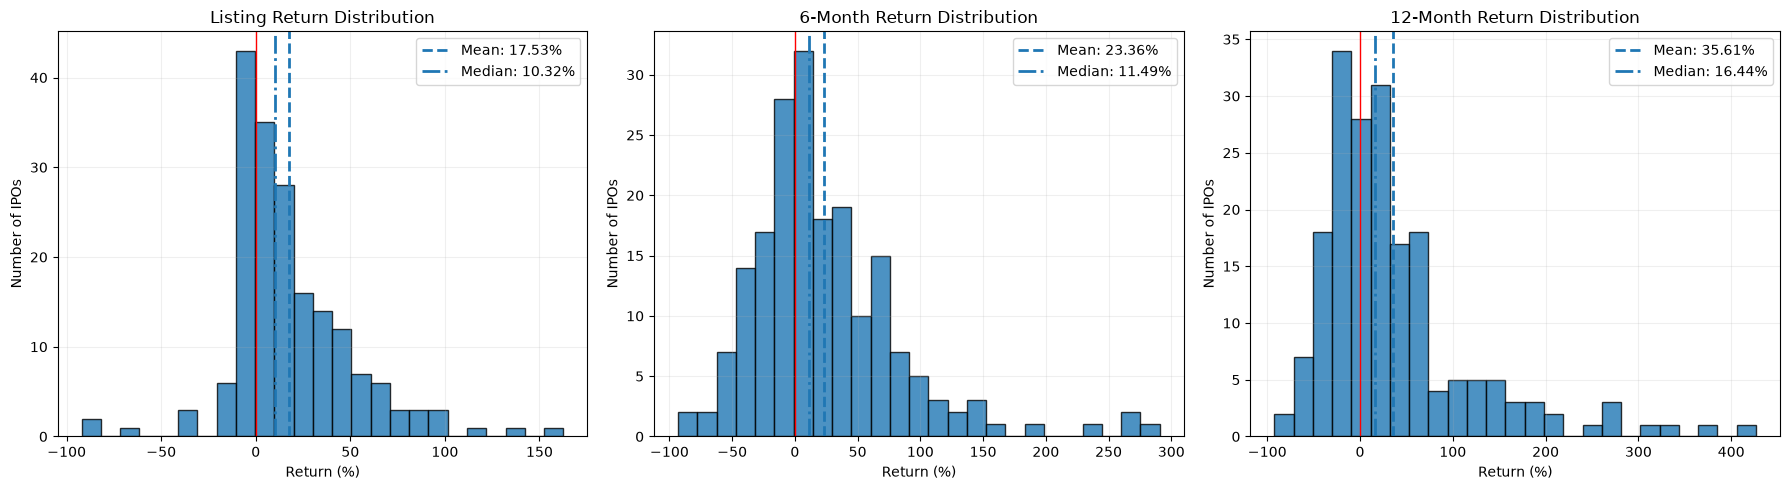

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

plot_columns = [
    "LISTING RETURN (%)",
    "6M RETURN (%)",
    "12M RETURN (%)"
]

titles = [
    "Listing Return Distribution",
    "6-Month Return Distribution",
    "12-Month Return Distribution"
]

for ax, col, title in zip(axes, plot_columns, titles):

    data = ipo_master[col].dropna()

    ax.hist(data, bins=25, edgecolor="black", alpha=0.8)

    ax.axvline(
        data.mean(),
        linestyle="--",
        linewidth=2,
        label=f"Mean: {data.mean():.2f}%"
    )

    ax.axvline(
        data.median(),
        linestyle="-.",
        linewidth=2,
        label=f"Median: {data.median():.2f}%"
    )

    ax.axvline(0, color="red", linewidth=1)

    ax.set_title(title)
    ax.set_xlabel("Return (%)")
    ax.set_ylabel("Number of IPOs")
    ax.legend()
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

## 6. IPO Downside Risk Analysis

Evaluate the downside risk associated with IPO investments
using negative return frequency, severe loss frequency,
lower-tail returns and return dispersion.

Compare issue-price and listing-close investment strategies.

In [18]:
# Risk analysis function

def calculate_risk_metrics(series):

    data = series.dropna()

    return {
        "Available IPOs": len(data),

        "Average Return (%)": data.mean(),

        "Median Return (%)": data.median(),

        "Standard Deviation (%)": data.std(),

        "Best Return (%)": data.max(),

        "Worst Return (%)": data.min(),

        "5th Percentile (%)": data.quantile(0.05),

        "25th Percentile (%)": data.quantile(0.25),

        "75th Percentile (%)": data.quantile(0.75),

        "95th Percentile (%)": data.quantile(0.95),

        "Negative Return (%)": (data < 0).mean() * 100,

        "Loss Greater Than 20% (%)": (data < -20).mean() * 100,

        "Loss Greater Than 50% (%)": (data < -50).mean() * 100,

        "Positive Return (%)": (data > 0).mean() * 100
    }


risk_metrics = [
    "LISTING RETURN (%)",
    "6M RETURN (%)",
    "12M RETURN (%)",
    "LISTING TO 6M RETURN (%)",
    "LISTING TO 12M RETURN (%)"
]

risk_results = pd.DataFrame({
    col: calculate_risk_metrics(ipo_master[col])
    for col in risk_metrics
}).T

risk_results.round(2)

,Available IPOs,Average Return (%),Median Return (%),Standard Deviation (%),Best Return (%),Worst Return (%),5th Percentile (%),25th Percentile (%),75th Percentile (%),95th Percentile (%),Negative Return (%),Loss Greater Than 20% (%),Loss Greater Than 50% (%),Positive Return (%)
LISTING RETURN (%),185.00,17.53,10.32,33.10,162.60,-92.02,-12.27,-2.73,32.18,78.31,30.81,3.24,1.62,69.19
6M RETURN (%),190.00,23.36,11.49,60.47,290.68,-93.15,-49.87,-15.79,54.67,129.55,37.89,20.53,5.26,62.11
12M RETURN (%),190.00,35.61,16.44,83.65,426.62,-92.37,-47.67,-19.14,58.02,198.49,41.58,24.21,4.74,58.42
LISTING TO 6M RETURN (%),185.00,5.49,-3.43,42.66,187.97,-59.12,-47.92,-20.73,21.21,80.78,54.59,25.95,3.78,45.41
LISTING TO 12M RETURN (%),185.00,15.65,-1.01,61.69,261.06,-63.82,-49.00,-27.30,32.66,149.37,51.35,31.89,4.32,48.65


In [19]:
strategy_comparison = pd.DataFrame({
    "Issue Price - 6M": calculate_risk_metrics(
        ipo_master["6M RETURN (%)"]
    ),

    "Listing Close - 6M": calculate_risk_metrics(
        ipo_master["LISTING TO 6M RETURN (%)"]
    ),

    "Issue Price - 12M": calculate_risk_metrics(
        ipo_master["12M RETURN (%)"]
    ),

    "Listing Close - 12M": calculate_risk_metrics(
        ipo_master["LISTING TO 12M RETURN (%)"]
    )
}).T

strategy_comparison.round(2)

,Available IPOs,Average Return (%),Median Return (%),Standard Deviation (%),Best Return (%),Worst Return (%),5th Percentile (%),25th Percentile (%),75th Percentile (%),95th Percentile (%),Negative Return (%),Loss Greater Than 20% (%),Loss Greater Than 50% (%),Positive Return (%)
Issue Price - 6M,190.00,23.36,11.49,60.47,290.68,-93.15,-49.87,-15.79,54.67,129.55,37.89,20.53,5.26,62.11
Listing Close - 6M,185.00,5.49,-3.43,42.66,187.97,-59.12,-47.92,-20.73,21.21,80.78,54.59,25.95,3.78,45.41
Issue Price - 12M,190.00,35.61,16.44,83.65,426.62,-92.37,-47.67,-19.14,58.02,198.49,41.58,24.21,4.74,58.42
Listing Close - 12M,185.00,15.65,-1.01,61.69,261.06,-63.82,-49.00,-27.30,32.66,149.37,51.35,31.89,4.32,48.65


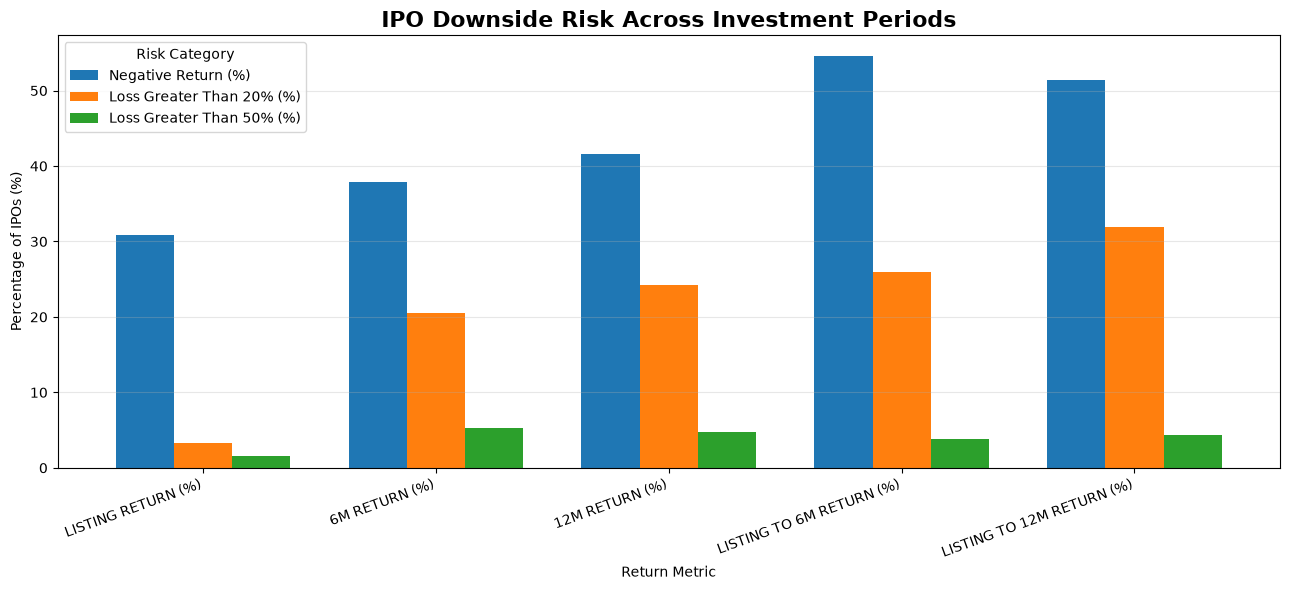

In [20]:
risk_plot = risk_results[
    [
        "Negative Return (%)",
        "Loss Greater Than 20% (%)",
        "Loss Greater Than 50% (%)"
    ]
]

ax = risk_plot.plot(
    kind="bar",
    figsize=(13, 6),
    width=0.75
)

plt.title(
    "IPO Downside Risk Across Investment Periods",
    fontsize=16,
    fontweight="bold"
)

plt.ylabel("Percentage of IPOs (%)")
plt.xlabel("Return Metric")

plt.xticks(rotation=20, ha="right")
plt.legend(title="Risk Category")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Paired Investment Strategy Comparison

Compare issue-price and listing-close investment returns
using only IPOs with valid observations for both strategies.

This ensures a like-for-like comparison.

In [21]:
# Create matched samples for 6-month and 12-month returns

paired_6m = ipo_master.dropna(
    subset=[
        "6M RETURN (%)",
        "LISTING TO 6M RETURN (%)"
    ]
).copy()

paired_12m = ipo_master.dropna(
    subset=[
        "12M RETURN (%)",
        "LISTING TO 12M RETURN (%)"
    ]
).copy()

print("Matched IPOs - 6M:", len(paired_6m))
print("Matched IPOs - 12M:", len(paired_12m))

Matched IPOs - 6M: 185
Matched IPOs - 12M: 185


In [22]:
def compare_strategies(df, issue_col, listing_col):

    issue = df[issue_col]
    listing = df[listing_col]

    return {
        "Matched IPOs": len(df),

        "Issue Price Mean (%)": issue.mean(),
        "Listing Close Mean (%)": listing.mean(),

        "Issue Price Median (%)": issue.median(),
        "Listing Close Median (%)": listing.median(),

        "Mean Return Difference (pp)": (
            issue - listing
        ).mean(),

        "Median Return Difference (pp)": (
            issue - listing
        ).median(),

        "Issue Price Profitable (%)": (
            issue > 0
        ).mean() * 100,

        "Listing Close Profitable (%)": (
            listing > 0
        ).mean() * 100,

        "Issue Price Severe Loss (%)": (
            issue < -20
        ).mean() * 100,

        "Listing Close Severe Loss (%)": (
            listing < -20
        ).mean() * 100
    }


paired_comparison = pd.DataFrame({
    "6 Months": compare_strategies(
        paired_6m,
        "6M RETURN (%)",
        "LISTING TO 6M RETURN (%)"
    ),

    "12 Months": compare_strategies(
        paired_12m,
        "12M RETURN (%)",
        "LISTING TO 12M RETURN (%)"
    )
}).T

paired_comparison.round(2)

,Matched IPOs,Issue Price Mean (%),Listing Close Mean (%),Issue Price Median (%),Listing Close Median (%),Mean Return Difference (pp),Median Return Difference (pp),Issue Price Profitable (%),Listing Close Profitable (%),Issue Price Severe Loss (%),Listing Close Severe Loss (%)
6 Months,185.00,23.41,5.49,11.68,-3.43,17.93,10.22,62.70,45.41,20.54,25.95
12 Months,185.00,35.65,15.65,15.93,-1.01,20.00,10.02,58.38,48.65,24.32,31.89


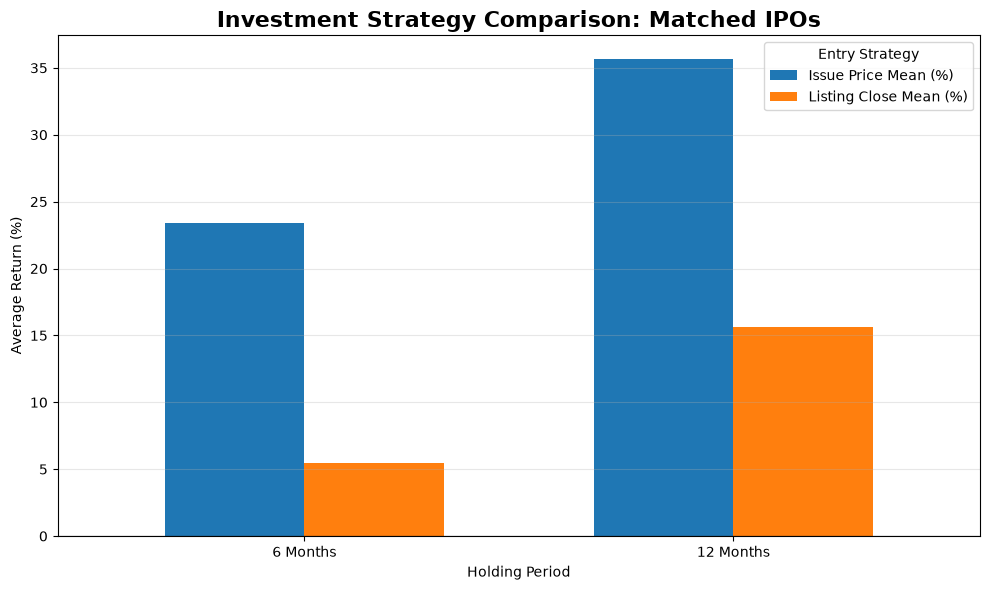

In [23]:
paired_chart = paired_comparison[
    [
        "Issue Price Mean (%)",
        "Listing Close Mean (%)"
    ]
]

ax = paired_chart.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.65
)

plt.title(
    "Investment Strategy Comparison: Matched IPOs",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Holding Period")
plt.ylabel("Average Return (%)")
plt.axhline(0, color="black", linewidth=0.8)

plt.xticks(rotation=0)
plt.legend(title="Entry Strategy")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [25]:
from scipy.stats import wilcoxon

# Calculate paired return differences
diff_6m = (
    paired_6m["6M RETURN (%)"]
    - paired_6m["LISTING TO 6M RETURN (%)"]
)

diff_12m = (
    paired_12m["12M RETURN (%)"]
    - paired_12m["LISTING TO 12M RETURN (%)"]
)

# Wilcoxon signed-rank tests
test_6m = wilcoxon(diff_6m)
test_12m = wilcoxon(diff_12m)

print("6-Month Wilcoxon Test")
print("Statistic:", test_6m.statistic)
print("P-value:", test_6m.pvalue)

print("\n12-Month Wilcoxon Test")
print("Statistic:", test_12m.statistic)
print("P-value:", test_12m.pvalue)

6-Month Wilcoxon Test
Statistic: 3557.0
P-value: 4.580651917868947e-12

12-Month Wilcoxon Test
Statistic: 3611.0
P-value: 7.703392625600962e-12


## 8. Sector-wise IPO Performance and Risk Analysis

Analyse IPO returns across sectors using average returns,
median returns, profitable IPO percentages and severe-loss
frequencies.

Compare issue-price and listing-close investment strategies.

In [26]:
sector_analysis = ipo_master.copy()

sector_metrics = [
    "LISTING RETURN (%)",
    "6M RETURN (%)",
    "12M RETURN (%)",
    "LISTING TO 6M RETURN (%)",
    "LISTING TO 12M RETURN (%)"
]

sector_summary = (
    sector_analysis
    .groupby("SECTOR")
    .agg(
        IPO_COUNT=("COMPANY NAME", "count"),

        AVG_LISTING_RETURN=("LISTING RETURN (%)", "mean"),
        MEDIAN_LISTING_RETURN=("LISTING RETURN (%)", "median"),

        AVG_6M_RETURN=("6M RETURN (%)", "mean"),
        MEDIAN_6M_RETURN=("6M RETURN (%)", "median"),

        AVG_12M_RETURN=("12M RETURN (%)", "mean"),
        MEDIAN_12M_RETURN=("12M RETURN (%)", "median"),

        AVG_LISTING_TO_6M=("LISTING TO 6M RETURN (%)", "mean"),
        MEDIAN_LISTING_TO_6M=("LISTING TO 6M RETURN (%)", "median"),

        AVG_LISTING_TO_12M=("LISTING TO 12M RETURN (%)", "mean"),
        MEDIAN_LISTING_TO_12M=("LISTING TO 12M RETURN (%)", "median")
    )
    .round(2)
    .sort_values("AVG_12M_RETURN", ascending=False)
)

sector_summary

,IPO_COUNT,AVG_LISTING_RETURN,MEDIAN_LISTING_RETURN,AVG_6M_RETURN,MEDIAN_6M_RETURN,AVG_12M_RETURN,MEDIAN_12M_RETURN,AVG_LISTING_TO_6M,MEDIAN_LISTING_TO_6M,AVG_LISTING_TO_12M,MEDIAN_LISTING_TO_12M
SECTOR,,,,,,,,,,,
Communication Services,2,16.93,16.93,71.18,71.18,67.55,67.55,36.59,36.59,31.31,31.31
Technology,25,35.58,7.70,36.20,16.60,66.29,20.05,0.63,-9.21,23.85,-10.09
Industrials,49,22.90,27.72,39.50,33.70,54.94,18.66,13.09,5.47,24.63,-3.56
Real Estate,8,5.93,3.75,29.50,1.68,46.61,7.59,19.50,-6.52,35.23,4.20
Healthcare,22,12.99,19.48,20.32,19.09,42.05,32.76,5.83,4.60,21.51,14.63
Consumer Cyclical,35,12.34,9.54,14.29,7.85,24.97,19.99,4.37,-3.04,15.46,5.00
Financial Services,19,19.33,6.10,18.62,12.94,17.85,11.24,1.50,-4.90,2.27,1.08
Energy,3,78.34,78.34,1.82,1.82,12.14,12.14,-33.46,-33.46,-24.25,-24.25
Basic Materials,15,10.69,12.36,14.14,5.19,3.88,-0.33,0.90,-13.16,-4.40,-6.93


In [27]:
sector_risk_results = []

for sector, group in sector_analysis.groupby("SECTOR"):

    row = {
        "SECTOR": sector,
        "TOTAL IPOs": len(group)
    }

    for col, label in {
        "LISTING RETURN (%)": "LISTING",
        "6M RETURN (%)": "6M",
        "12M RETURN (%)": "12M",
        "LISTING TO 6M RETURN (%)": "LISTING TO 6M",
        "LISTING TO 12M RETURN (%)": "LISTING TO 12M"
    }.items():

        returns = group[col].dropna()

        row[f"{label} SAMPLE"] = len(returns)

        row[f"{label} PROFITABLE (%)"] = (
            (returns > 0).mean() * 100
        )

        row[f"{label} LOSS >20 (%)"] = (
            (returns < -20).mean() * 100
        )

        row[f"{label} MEDIAN (%)"] = returns.median()

    sector_risk_results.append(row)

sector_risk = pd.DataFrame(sector_risk_results)

sector_risk.round(2)

,SECTOR,TOTAL IPOs,LISTING SAMPLE,LISTING PROFITABLE (%),LISTING LOSS >20 (%),LISTING MEDIAN (%),6M SAMPLE,6M PROFITABLE (%),6M LOSS >20 (%),6M MEDIAN (%),12M SAMPLE,12M PROFITABLE (%),12M LOSS >20 (%),12M MEDIAN (%),LISTING TO 6M SAMPLE,LISTING TO 6M PROFITABLE (%),LISTING TO 6M LOSS >20 (%),LISTING TO 6M MEDIAN (%),LISTING TO 12M SAMPLE,LISTING TO 12M PROFITABLE (%),LISTING TO 12M LOSS >20 (%),LISTING TO 12M MEDIAN (%)
0,Basic Materials,15,13,69.23,0.00,12.36,15,53.33,20.00,5.19,15,46.67,26.67,-0.33,13,38.46,30.77,-13.16,13,38.46,30.77,-6.93
1,Communication Services,2,2,50.00,0.00,16.93,2,50.00,0.00,71.18,2,50.00,50.00,67.55,2,50.00,0.00,36.59,2,50.00,50.00,31.31
2,Consumer Cyclical,35,35,71.43,2.86,9.54,35,62.86,20.00,7.85,35,62.86,17.14,19.99,35,42.86,25.71,-3.04,35,51.43,20.00,5.00
3,Consumer Defensive,11,11,54.55,9.09,3.02,11,45.45,36.36,-9.47,11,36.36,45.45,-19.05,11,45.45,27.27,-6.59,11,36.36,54.55,-23.92
4,Energy,3,1,100.00,0.00,78.34,2,50.00,0.00,1.82,2,50.00,0.00,12.14,1,0.00,100.00,-33.46,1,0.00,100.00,-24.25
5,Financial Services,19,18,72.22,0.00,6.10,18,72.22,11.11,12.94,18,61.11,16.67,11.24,18,44.44,22.22,-4.90,18,50.00,27.78,1.08
6,Healthcare,22,21,71.43,9.52,19.48,22,72.73,9.09,19.09,22,72.73,22.73,32.76,21,52.38,4.76,4.60,21,71.43,19.05,14.63
7,Industrials,49,46,73.91,4.35,27.72,47,61.70,21.28,33.70,47,59.57,23.40,18.66,46,54.35,26.09,5.47,46,45.65,36.96,-3.56
8,Real Estate,8,8,62.50,0.00,3.75,8,50.00,25.00,1.68,8,62.50,25.00,7.59,8,25.00,12.50,-6.52,8,62.50,25.00,4.20
9,Technology,25,25,68.00,0.00,7.70,25,72.00,24.00,16.60,25,60.00,24.00,20.05,25,44.00,40.00,-9.21,25,44.00,40.00,-10.09


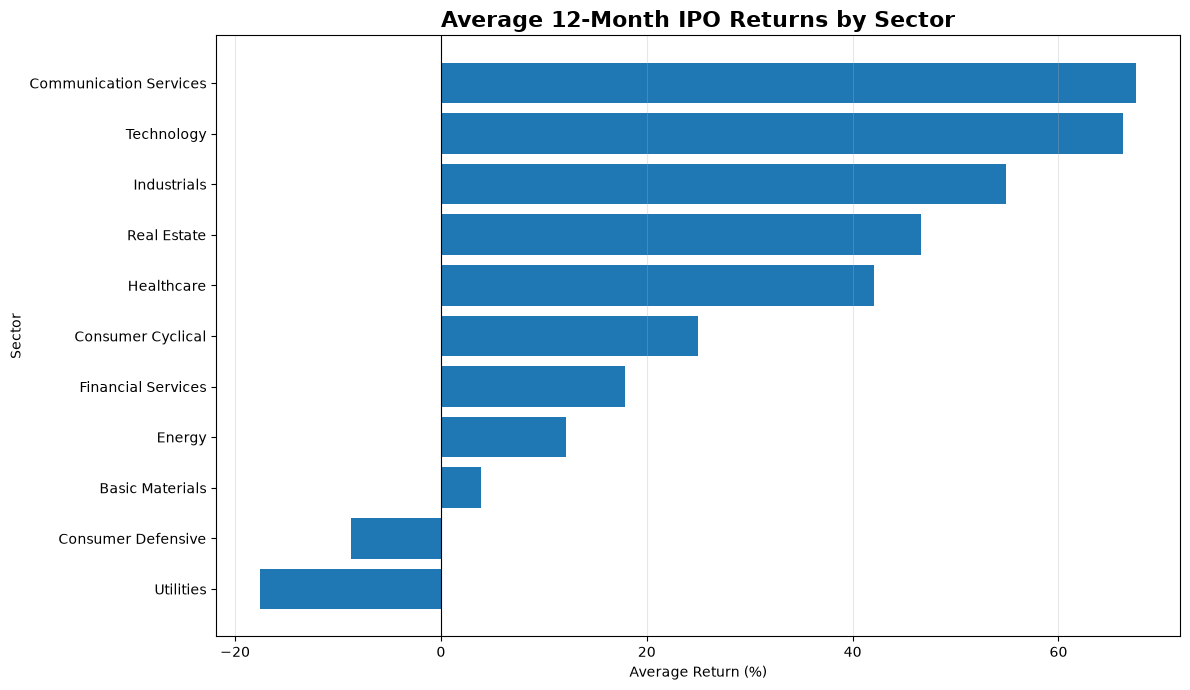

In [28]:
sector_plot = sector_summary.sort_values(
    "AVG_12M_RETURN",
    ascending=True
)

plt.figure(figsize=(12, 7))

plt.barh(
    sector_plot.index,
    sector_plot["AVG_12M_RETURN"]
)

plt.axvline(0, color="black", linewidth=0.8)

plt.title(
    "Average 12-Month IPO Returns by Sector",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Average Return (%)")
plt.ylabel("Sector")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

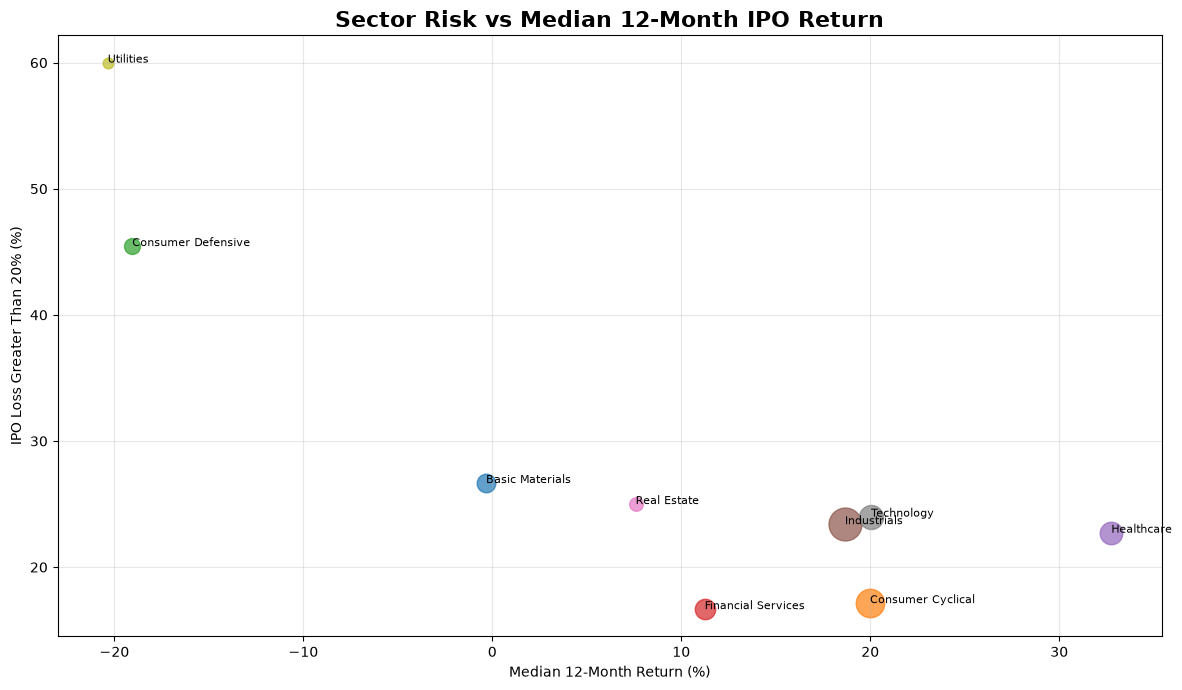

In [29]:
plt.figure(figsize=(12, 7))

for sector, group in sector_analysis.groupby("SECTOR"):

    returns = group["12M RETURN (%)"].dropna()

    if len(returns) < 5:
        continue

    plt.scatter(
        returns.median(),
        (returns < -20).mean() * 100,
        s=len(returns) * 12,
        alpha=0.7
    )

    plt.annotate(
        sector,
        (
            returns.median(),
            (returns < -20).mean() * 100
        ),
        fontsize=8
    )

plt.title(
    "Sector Risk vs Median 12-Month IPO Return",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Median 12-Month Return (%)")
plt.ylabel("IPO Loss Greater Than 20% (%)")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 9. IPO Subscription and Investor Demand Analysis

Investigate the relationship between QIB, NII, retail and
total IPO subscription multiples and subsequent IPO returns.

Use only verified final subscription records.

In [30]:
subscription_columns = [
    "QIB SUBSCRIPTION",
    "NII SUBSCRIPTION",
    "RETAIL SUBSCRIPTION",
    "TOTAL SUBSCRIPTION"
]

subscription_quality = ipo_master[
    subscription_columns
].describe().T

subscription_quality

,count,mean,std,min,25%,50%,75%,max
QIB SUBSCRIPTION,190.00,77.80,76.53,1.01,8.62,51.31,134.06,331.60
NII SUBSCRIPTION,190.00,52.14,76.60,0.20,3.85,28.30,63.20,503.83
RETAIL SUBSCRIPTION,190.00,18.91,33.53,0.11,2.13,7.13,21.17,246.94
TOTAL SUBSCRIPTION,190.00,43.68,46.39,0.53,4.71,27.16,69.36,229.68


In [31]:
print(
    ipo_master["DATA STATUS"]
    .value_counts(dropna=False)
)

print("\nSubscription basis:")

print(
    ipo_master["SUBSCRIPTION BASIS"]
    .value_counts(dropna=False)
)

print("\nFinal data status:")

print(
    ipo_master["FINAL DATA"]
    .value_counts(dropna=False)
)

DATA STATUS
Collected                            190
Not available in API                   3
Bids only - multiples unavailable      1
Name: count, dtype: int64

Subscription basis:
SUBSCRIPTION BASIS
exact          190
unavailable      3
bids_only        1
Name: count, dtype: int64

Final data status:
FINAL DATA
True     191
False      3
Name: count, dtype: int64


In [32]:
subscription_analysis = ipo_master[
    [
        "COMPANY NAME",
        "SYMBOL",
        "SECTOR",
        "TOTAL SUBSCRIPTION",
        "QIB SUBSCRIPTION",
        "NII SUBSCRIPTION",
        "RETAIL SUBSCRIPTION",
        "LISTING RETURN (%)",
        "6M RETURN (%)",
        "12M RETURN (%)",
        "LISTING TO 6M RETURN (%)",
        "LISTING TO 12M RETURN (%)",
        "DATA STATUS",
        "SUBSCRIPTION BASIS",
        "FINAL DATA"
    ]
].copy()

# Keep only verified final subscription observations
subscription_analysis = subscription_analysis[
    (subscription_analysis["FINAL DATA"] == True) &
    (subscription_analysis["SUBSCRIPTION BASIS"] == "exact")
].copy()

print("Verified subscription records:", len(subscription_analysis))

subscription_analysis.head()

Verified subscription records: 190


,COMPANY NAME,SYMBOL,SECTOR,TOTAL SUBSCRIPTION,QIB SUBSCRIPTION,NII SUBSCRIPTION,RETAIL SUBSCRIPTION,LISTING RETURN (%),6M RETURN (%),12M RETURN (%),LISTING TO 6M RETURN (%),LISTING TO 12M RETURN (%),DATA STATUS,SUBSCRIPTION BASIS,FINAL DATA
0,Fusion Micro Finance Limited,FUSION,Financial Services,2.95,8.59,1.38,0.51,-11.74,22.47,62.27,38.76,83.85,Collected,exact,True
1,Global Health Limited,MEDANTA,Healthcare,9.58,28.64,4.02,0.88,NaN,70.39,164.43,NaN,NaN,Collected,exact,True
2,Bikaji Foods International Limited,BIKAJI,Consumer Defensive,26.67,80.63,7.10,4.77,5.82,23.28,83.03,16.51,72.97,Collected,exact,True
4,FiveStar Business Finance Limited,FIVESTAR,Financial Services,0.70,1.77,0.61,0.11,3.38,11.68,69.54,8.03,64.00,Collected,exact,True
5,Kaynes Technology India Limited,KAYNES,Technology,34.16,98.47,21.21,4.10,17.54,122.65,324.39,89.43,261.06,Collected,exact,True


In [33]:
from scipy.stats import spearmanr

subscription_types = [
    "QIB SUBSCRIPTION",
    "NII SUBSCRIPTION",
    "RETAIL SUBSCRIPTION",
    "TOTAL SUBSCRIPTION"
]

return_types = [
    "LISTING RETURN (%)",
    "6M RETURN (%)",
    "12M RETURN (%)"
]

correlation_results = []

for sub_col in subscription_types:

    for return_col in return_types:

        temp = subscription_analysis[
            [sub_col, return_col]
        ].dropna()

        if len(temp) < 5:
            continue

        corr, p_value = spearmanr(
            temp[sub_col],
            temp[return_col]
        )

        correlation_results.append({
            "Subscription Category": sub_col,
            "Return Metric": return_col,
            "Sample Size": len(temp),
            "Spearman Correlation": corr,
            "P-value": p_value
        })

correlation_df = pd.DataFrame(correlation_results)

correlation_df.round(4)

,Subscription Category,Return Metric,Sample Size,Spearman Correlation,P-value
0,QIB SUBSCRIPTION,LISTING RETURN (%),182,0.67,0.00
1,QIB SUBSCRIPTION,6M RETURN (%),186,0.36,0.00
2,QIB SUBSCRIPTION,12M RETURN (%),186,0.30,0.00
3,NII SUBSCRIPTION,LISTING RETURN (%),182,0.59,0.00
4,NII SUBSCRIPTION,6M RETURN (%),186,0.25,0.00
5,NII SUBSCRIPTION,12M RETURN (%),186,0.17,0.02
6,RETAIL SUBSCRIPTION,LISTING RETURN (%),182,0.53,0.00
7,RETAIL SUBSCRIPTION,6M RETURN (%),186,0.23,0.00
8,RETAIL SUBSCRIPTION,12M RETURN (%),186,0.17,0.02
9,TOTAL SUBSCRIPTION,LISTING RETURN (%),182,0.69,0.00


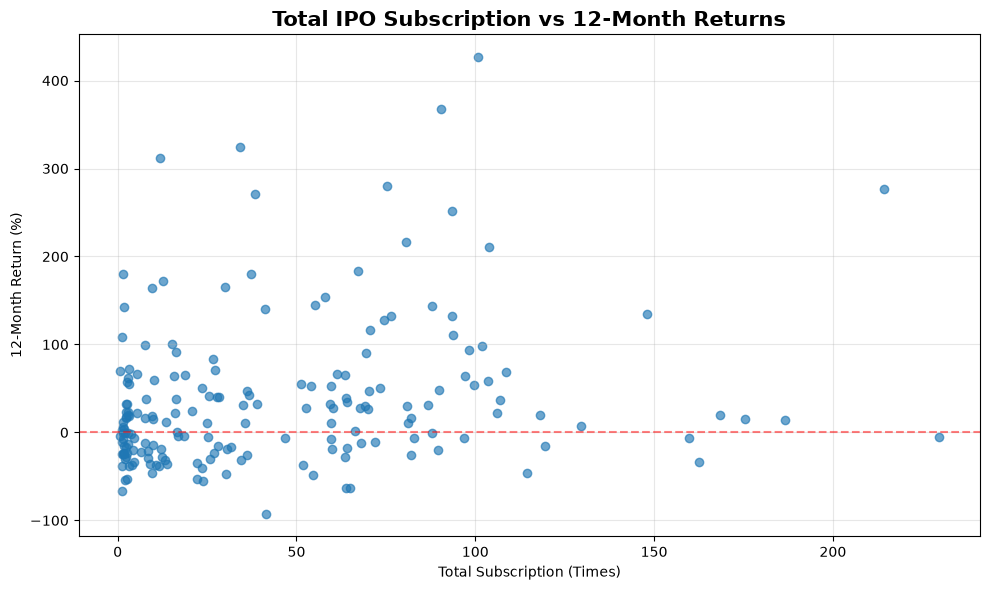

In [34]:
plt.figure(figsize=(10, 6))

plt.scatter(
    subscription_analysis["TOTAL SUBSCRIPTION"],
    subscription_analysis["12M RETURN (%)"],
    alpha=0.65
)

plt.axhline(0, color="red", linestyle="--", alpha=0.5)

plt.title(
    "Total IPO Subscription vs 12-Month Returns",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Total Subscription (Times)")
plt.ylabel("12-Month Return (%)")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [35]:
correlation_df.style.format({
    "Spearman Correlation": "{:.3f}",
    "P-value": "{:.3e}"
})

,Subscription Category,Return Metric,Sample Size,Spearman Correlation,P-value
0,QIB SUBSCRIPTION,LISTING RETURN (%),182,0.673,2.303e-25
1,QIB SUBSCRIPTION,6M RETURN (%),186,0.360,4.469e-07
2,QIB SUBSCRIPTION,12M RETURN (%),186,0.301,2.986e-05
3,NII SUBSCRIPTION,LISTING RETURN (%),182,0.586,3.521e-18
4,NII SUBSCRIPTION,6M RETURN (%),186,0.255,4.521e-04
5,NII SUBSCRIPTION,12M RETURN (%),186,0.167,2.261e-02
6,RETAIL SUBSCRIPTION,LISTING RETURN (%),182,0.528,1.811e-14
7,RETAIL SUBSCRIPTION,6M RETURN (%),186,0.229,1.649e-03
8,RETAIL SUBSCRIPTION,12M RETURN (%),186,0.166,2.361e-02
9,TOTAL SUBSCRIPTION,LISTING RETURN (%),182,0.686,1.326e-26


## 10. Subscription-Level Segmentation

Segment IPOs into four groups based on total subscription multiples.
Compare their listing, 6-month and 12-month returns, profitability
and downside risk.

In [36]:
# Create a copy of verified subscription data
subscription_bands = subscription_analysis.copy()

# Divide IPOs into four equally sized groups
subscription_bands["SUBSCRIPTION QUARTILE"] = pd.qcut(
    subscription_bands["TOTAL SUBSCRIPTION"].rank(method="first"),
    q=4,
    labels=["Q1 - Lowest", "Q2 - Lower Middle",
            "Q3 - Upper Middle", "Q4 - Highest"]
)

# Inspect subscription ranges
subscription_ranges = (
    subscription_bands
    .groupby("SUBSCRIPTION QUARTILE", observed=True)
    ["TOTAL SUBSCRIPTION"]
    .agg(["count", "min", "median", "max"])
    .round(2)
)

subscription_ranges

,count,min,median,max
SUBSCRIPTION QUARTILE,,,,
Q1 - Lowest,48,0.53,2.20,4.50
Q2 - Lower Middle,47,5.33,13.21,27.05
Q3 - Upper Middle,47,27.28,52.70,69.14
Q4 - Highest,48,69.43,95.34,229.68


In [37]:
subscription_quartile_results = []

return_columns = {
    "LISTING RETURN (%)": "LISTING",
    "6M RETURN (%)": "6M",
    "12M RETURN (%)": "12M",
    "LISTING TO 6M RETURN (%)": "LISTING TO 6M",
    "LISTING TO 12M RETURN (%)": "LISTING TO 12M"
}

for quartile, group in subscription_bands.groupby(
    "SUBSCRIPTION QUARTILE",
    observed=True
):

    row = {
        "SUBSCRIPTION GROUP": quartile,
        "IPO COUNT": len(group),
        "MEDIAN SUBSCRIPTION": group["TOTAL SUBSCRIPTION"].median()
    }

    for col, label in return_columns.items():

        values = group[col].dropna()

        row[f"{label} AVG (%)"] = values.mean()
        row[f"{label} MEDIAN (%)"] = values.median()
        row[f"{label} PROFITABLE (%)"] = (
            values.gt(0).mean() * 100
        )
        row[f"{label} LOSS >20 (%)"] = (
            values.lt(-20).mean() * 100
        )

    subscription_quartile_results.append(row)

subscription_quartile_summary = pd.DataFrame(
    subscription_quartile_results
)

subscription_quartile_summary.round(2)

,SUBSCRIPTION GROUP,IPO COUNT,MEDIAN SUBSCRIPTION,LISTING AVG (%),LISTING MEDIAN (%),LISTING PROFITABLE (%),LISTING LOSS >20 (%),6M AVG (%),6M MEDIAN (%),6M PROFITABLE (%),6M LOSS >20 (%),12M AVG (%),12M MEDIAN (%),12M PROFITABLE (%),12M LOSS >20 (%),LISTING TO 6M AVG (%),LISTING TO 6M MEDIAN (%),LISTING TO 6M PROFITABLE (%),LISTING TO 6M LOSS >20 (%),LISTING TO 12M AVG (%),LISTING TO 12M MEDIAN (%),LISTING TO 12M PROFITABLE (%),LISTING TO 12M LOSS >20 (%)
0,Q1 - Lowest,48,2.20,-3.17,-4.30,33.33,2.22,-3.56,-8.03,39.13,36.96,7.76,-1.38,43.48,32.61,0.43,-8.58,37.78,28.89,11.58,-2.78,44.44,31.11
1,Q2 - Lower Middle,47,13.21,5.31,5.20,59.09,2.27,15.83,9.57,60.87,15.22,21.08,5.41,52.17,34.78,7.38,-1.56,47.73,20.45,11.95,2.13,52.27,36.36
2,Q3 - Upper Middle,47,52.70,21.67,20.85,85.11,4.26,26.35,18.67,68.09,21.28,39.45,30.41,63.83,19.15,4.36,-7.91,40.43,29.79,15.87,-1.28,46.81,29.79
3,Q4 - Highest,48,95.34,48.01,41.57,97.83,2.17,58.49,55.88,82.98,6.38,78.22,47.56,76.60,8.51,10.09,5.16,54.35,23.91,24.00,0.96,52.17,32.61


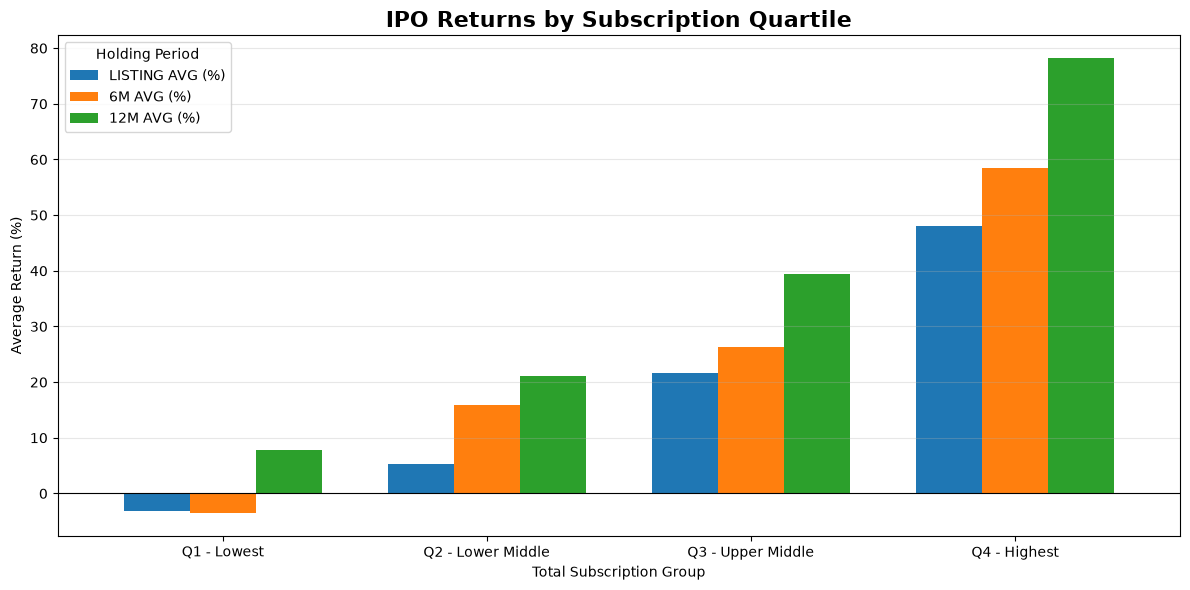

In [38]:
quartile_plot = subscription_quartile_summary.set_index(
    "SUBSCRIPTION GROUP"
)[
    [
        "LISTING AVG (%)",
        "6M AVG (%)",
        "12M AVG (%)"
    ]
]

ax = quartile_plot.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.75
)

plt.title(
    "IPO Returns by Subscription Quartile",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Total Subscription Group")
plt.ylabel("Average Return (%)")

plt.axhline(0, color="black", linewidth=0.8)
plt.xticks(rotation=0)
plt.legend(title="Holding Period")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

ModuleNotFoundError: No module named 'seaborn'

In [45]:
import seaborn as sns

correlation_matrix = subscription_analysis[
    subscription_types + return_types
].corr(method="spearman")

plt.figure(figsize=(11, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="RdYlGn",
    center=0,
    fmt=".2f",
    linewidths=0.5
)

plt.title(
    "Spearman Correlation: IPO Subscription and Returns",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

ModuleNotFoundError: No module named 'seaborn'

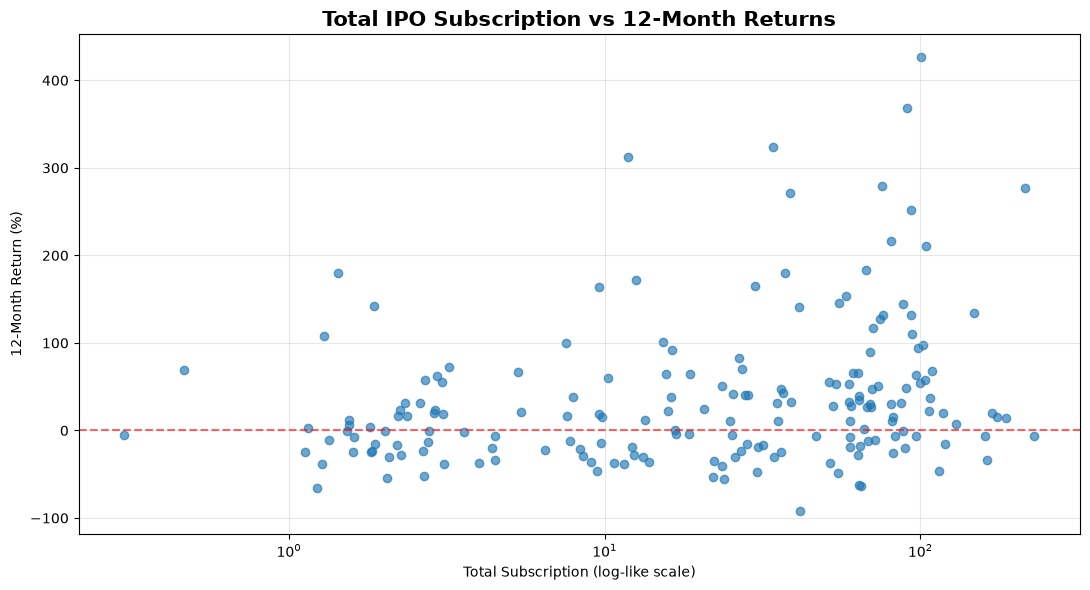

In [46]:
plt.figure(figsize=(11, 6))

plt.scatter(
    subscription_analysis["TOTAL SUBSCRIPTION"],
    subscription_analysis["12M RETURN (%)"],
    alpha=0.65
)

plt.xscale("symlog", linthresh=1)

plt.axhline(0, color="red", linestyle="--", alpha=0.6)

plt.title(
    "Total IPO Subscription vs 12-Month Returns",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Total Subscription (log-like scale)")
plt.ylabel("12-Month Return (%)")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

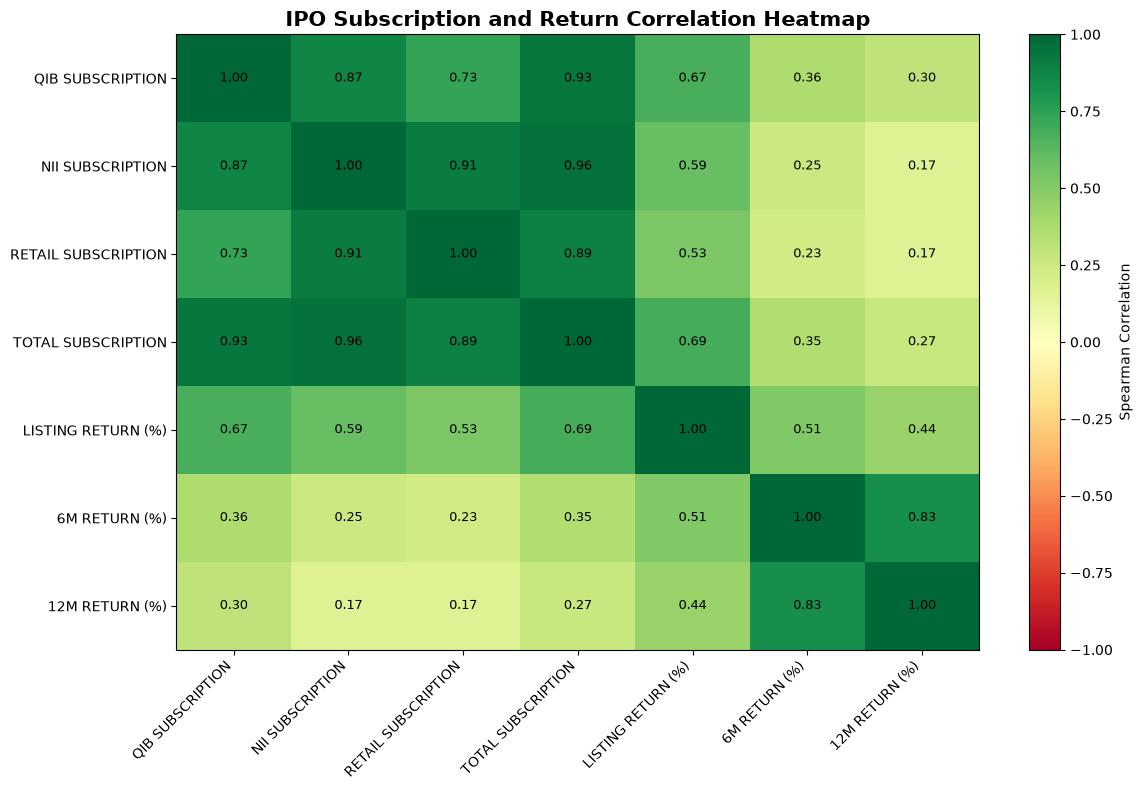

In [47]:
import matplotlib.pyplot as plt
import numpy as np

correlation_matrix = subscription_analysis[
    subscription_types + return_types
].corr(method="spearman")

fig, ax = plt.subplots(figsize=(12, 8))

image = ax.imshow(
    correlation_matrix,
    cmap="RdYlGn",
    vmin=-1,
    vmax=1,
    aspect="auto"
)

ax.set_xticks(range(len(correlation_matrix.columns)))
ax.set_yticks(range(len(correlation_matrix.index)))

ax.set_xticklabels(
    correlation_matrix.columns,
    rotation=45,
    ha="right"
)

ax.set_yticklabels(correlation_matrix.index)

for i in range(len(correlation_matrix.index)):
    for j in range(len(correlation_matrix.columns)):

        value = correlation_matrix.iloc[i, j]

        ax.text(
            j, i,
            f"{value:.2f}",
            ha="center",
            va="center",
            fontsize=9
        )

plt.colorbar(image, ax=ax, label="Spearman Correlation")

plt.title(
    "IPO Subscription and Return Correlation Heatmap",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [48]:
print(subscription_quartile_summary.columns.tolist())

display(
    subscription_quartile_summary.to_string(index=False)
)

['SUBSCRIPTION GROUP', 'IPO COUNT', 'MEDIAN SUBSCRIPTION', 'LISTING AVG (%)', 'LISTING MEDIAN (%)', 'LISTING PROFITABLE (%)', 'LISTING LOSS >20 (%)', '6M AVG (%)', '6M MEDIAN (%)', '6M PROFITABLE (%)', '6M LOSS >20 (%)', '12M AVG (%)', '12M MEDIAN (%)', '12M PROFITABLE (%)', '12M LOSS >20 (%)', 'LISTING TO 6M AVG (%)', 'LISTING TO 6M MEDIAN (%)', 'LISTING TO 6M PROFITABLE (%)', 'LISTING TO 6M LOSS >20 (%)', 'LISTING TO 12M AVG (%)', 'LISTING TO 12M MEDIAN (%)', 'LISTING TO 12M PROFITABLE (%)', 'LISTING TO 12M LOSS >20 (%)']


'SUBSCRIPTION GROUP  IPO COUNT  MEDIAN SUBSCRIPTION  LISTING AVG (%)  LISTING MEDIAN (%)  LISTING PROFITABLE (%)  LISTING LOSS >20 (%)  6M AVG (%)  6M MEDIAN (%)  6M PROFITABLE (%)  6M LOSS >20 (%)  12M AVG (%)  12M MEDIAN (%)  12M PROFITABLE (%)  12M LOSS >20 (%)  LISTING TO 6M AVG (%)  LISTING TO 6M MEDIAN (%)  LISTING TO 6M PROFITABLE (%)  LISTING TO 6M LOSS >20 (%)  LISTING TO 12M AVG (%)  LISTING TO 12M MEDIAN (%)  LISTING TO 12M PROFITABLE (%)  LISTING TO 12M LOSS >20 (%)\n       Q1 - Lowest         48                 2.21            -3.17               -4.30                   33.33                  2.22       -3.56          -8.03              39.13            36.96         7.76           -1.38               43.48             32.61                   0.43                     -8.58                         37.78                       28.89                   11.58                      -2.78                          44.44                        31.11\n Q2 - Lower Middle         47    

# 10. Nifty 50 Benchmark Analysis

## Objective
Compare IPO returns against the Nifty 50 benchmark using two entry strategies:
1. IPO issue price
2. IPO listing-day closing price

Holding periods:
- 6 months
- 12 months

The benchmark will use matched listing and observation dates.

In [49]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt

print("Dataset shape:", ipo_returns_df.shape)

print("\nColumns:")
print(ipo_returns_df.columns.tolist())

print("\nDate columns:")
for col in ["LISTING DATE", "6M ACTUAL DATE", "12M ACTUAL DATE"]:
    print(f"\n{col}")
    print(ipo_returns_df[col].head())

print("\nMissing values:")
print(
    ipo_returns_df[
        ["LISTING DATE", "6M ACTUAL DATE", "12M ACTUAL DATE"]
    ].isnull().sum()
)

NameError: name 'ipo_returns_df' is not defined

In [3]:
import pandas as pd

for name, obj in globals().items():
    if isinstance(obj, pd.DataFrame):
        print(name, obj.shape)

RuntimeError: dictionary changed size during iteration